Датасет

https://www.kaggle.com/datasets/shreyapmaher/fruits-dataset-images

Задачи обработки изображений
    Классификация: Что на картинке в целом?
    Классификация с локализацией (Object Detection): Где находятся    объекты и что это?
    Сегментация (Semantic/Instance): Попиксельное выделение объектов.
    Улучшение изображения (Enhancement/Restoration): Улучшить качество исходника.

In [40]:
from sklearn.model_selection import train_test_split
import cv2
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

root_directory = Path("images/")
images = []
labels = []
dataset_structure = {}

def scan_directory():
    if not root_directory.exists():
        raise FileNotFoundError(f"Директория {root_directory} не найдена")
    
    for category_path in root_directory.iterdir():
        if category_path.is_dir():                
            for file_path in category_path.iterdir():
                if file_path.suffix.lower() in {'.jpg', '.jpeg'}:
                    img = cv2.imread(str(file_path))
                    if img is not None:
                        images.append(img)
                        labels.append(category_path.name)
                        
                        flipped = cv2.flip(img, 1)
                        images.append(flipped)
                        labels.append(category_path.name)
    return images
    
    
scan_directory()
print(images.__len__())
print(labels)

labels_idx = {'apple': 0, 'banana': 1, 'cherry': 2, 'chickoo': 3, 'grapes': 4, 'kiwi': 5, 'orange': 6, 'strawberry': 7}



608
['apple', 'apple', 'apple', 'apple', 'apple', 'apple', 'apple', 'apple', 'apple', 'apple', 'apple', 'apple', 'apple', 'apple', 'apple', 'apple', 'apple', 'apple', 'apple', 'apple', 'apple', 'apple', 'apple', 'apple', 'apple', 'apple', 'apple', 'apple', 'apple', 'apple', 'apple', 'apple', 'apple', 'apple', 'apple', 'apple', 'apple', 'apple', 'apple', 'apple', 'apple', 'apple', 'apple', 'apple', 'apple', 'apple', 'apple', 'apple', 'apple', 'apple', 'apple', 'apple', 'apple', 'apple', 'apple', 'apple', 'apple', 'apple', 'apple', 'apple', 'apple', 'apple', 'apple', 'apple', 'apple', 'apple', 'apple', 'apple', 'apple', 'apple', 'banana', 'banana', 'banana', 'banana', 'banana', 'banana', 'banana', 'banana', 'banana', 'banana', 'banana', 'banana', 'banana', 'banana', 'banana', 'banana', 'banana', 'banana', 'banana', 'banana', 'banana', 'banana', 'banana', 'banana', 'banana', 'banana', 'banana', 'banana', 'banana', 'banana', 'banana', 'banana', 'banana', 'banana', 'banana', 'banana', 'bana

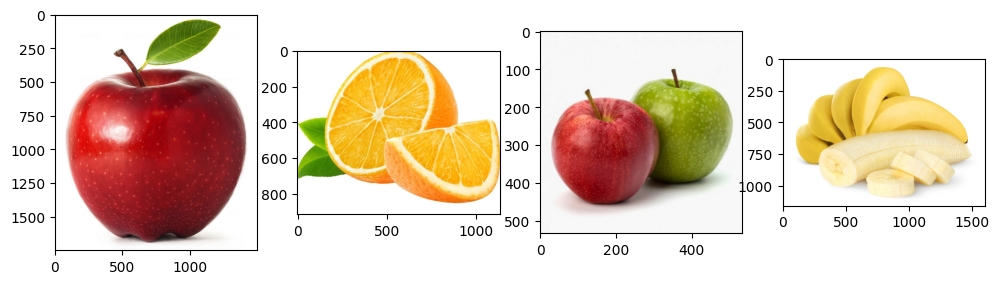

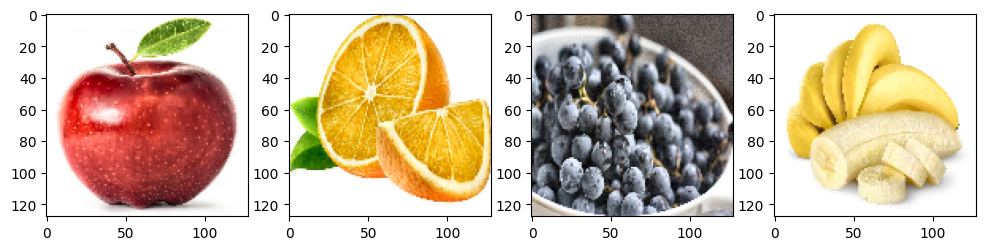

In [41]:
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score


def apply_clahe(img):
    resized = cv2.resize(img, (128, 128))
    
    clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
    lab = cv2.cvtColor(resized, cv2.COLOR_BGR2LAB)
    ll, la, lb = cv2.split(lab)
    l_enhanced = clahe.apply(ll)
    lab_enhanced = cv2.merge((l_enhanced, la, lb))
    image_clahe = cv2.cvtColor(lab_enhanced, cv2.COLOR_LAB2RGB)
    
    return image_clahe

image_clahe = np.array([apply_clahe(img) for img in images])


fig, axes = plt.subplots(1, 4, figsize=(12, 8))
axes[0].imshow(cv2.cvtColor(images[0], cv2.COLOR_BGR2RGB))
axes[1].imshow(cv2.cvtColor(images[500], cv2.COLOR_BGR2RGB))
axes[2].imshow(cv2.cvtColor(images[40], cv2.COLOR_BGR2RGB))
axes[3].imshow(cv2.cvtColor(images[100], cv2.COLOR_BGR2RGB))
plt.show()

fig, axes = plt.subplots(1, 4, figsize=(12, 8))
axes[0].imshow(image_clahe[0])
axes[1].imshow(image_clahe[500])
axes[2].imshow(image_clahe[300])
axes[3].imshow(image_clahe[100])
plt.show()
    

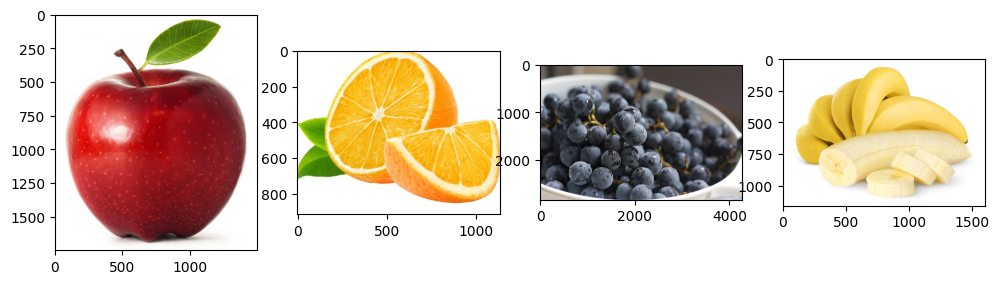

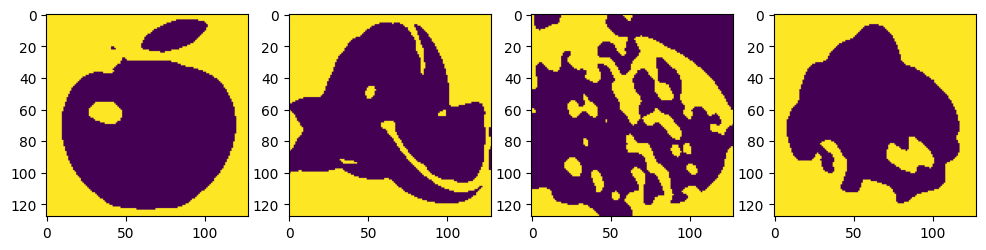

In [42]:
def apply_threshold(img):
    resized = cv2.resize(img, (128, 128))
    grey = cv2.cvtColor(resized, cv2.COLOR_BGR2GRAY)
    gaussian_new = cv2.GaussianBlur(grey, (0, 0), sigmaX=2)
    mean_val = gaussian_new.mean()
    _, labeled_mask = cv2.threshold(gaussian_new, mean_val, 255, cv2.THRESH_BINARY)
    
    return labeled_mask

image_threshold = np.array([apply_threshold(img) for img in images])

fig, axes = plt.subplots(1, 4, figsize=(12, 8))
axes[0].imshow(cv2.cvtColor(images[0], cv2.COLOR_BGR2RGB))
axes[1].imshow(cv2.cvtColor(images[500], cv2.COLOR_BGR2RGB))
axes[2].imshow(cv2.cvtColor(images[300], cv2.COLOR_BGR2RGB))
axes[3].imshow(cv2.cvtColor(images[100], cv2.COLOR_BGR2RGB))
plt.show()

fig, axes = plt.subplots(1, 4, figsize=(12, 8))
axes[0].imshow(image_threshold[0])
axes[1].imshow(image_threshold[500])
axes[2].imshow(image_threshold[300])
axes[3].imshow(image_threshold[100])
plt.show()

def threshold_features(img):
    mask = apply_threshold(img)
    return mask.flatten()



Accuracy (Canny + SVM): 0.4065934065934066
Accuracy (HOG + SVM): 0.5164835164835165


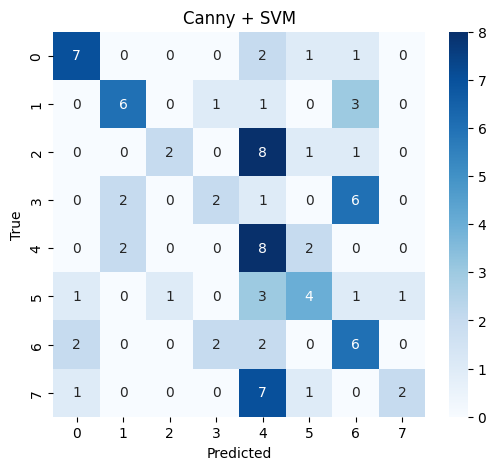

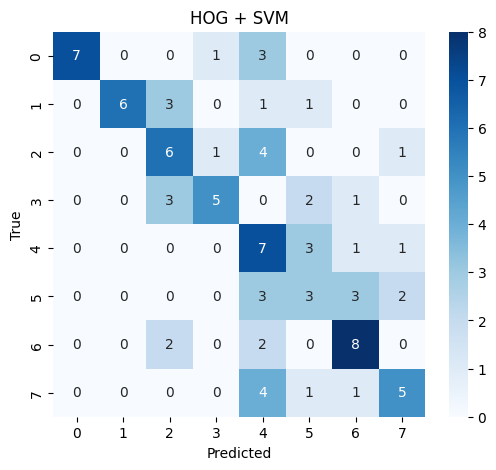

In [ ]:
from skimage.feature import hog
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt


images_resize = []
for img in images:
    resized = cv2.resize(img, (128, 128))
    images_resize.append(resized)
    
    
X_train, X_temp, y_train, y_temp = train_test_split(
    images_resize, labels,
    test_size=0.3,     
    random_state=42,
    stratify=labels
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp,
    test_size=0.5,
    random_state=42,
    stratify=y_temp
)


def threshold_features(img):
    mask = apply_threshold(img)
    return mask.flatten()

def apply_canny(img, t1=100, t2=200):
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    edges = cv2.Canny(gray, threshold1=t1, threshold2=t2)
    return edges

def flatten_edges(img):
    edges = apply_canny(img, 128)
    return edges.flatten()


def extract_hog_features(img):
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    features = hog(gray,
                   pixels_per_cell=(8, 8),
                   cells_per_block=(2, 2),
                   orientations=9,
                   block_norm='L2-Hys')
    return features

X_train_canny = np.array([flatten_edges(img) for img in X_train])
X_val_canny   = np.array([flatten_edges(img) for img in X_val])

X_train_hog = np.array([extract_hog_features(img) for img in X_train])
X_val_hog   = np.array([extract_hog_features(img) for img in X_val])

svm_canny = SVC(kernel='rbf', C=10, gamma='scale')
svm_canny.fit(X_train_canny, y_train)

y_pred_canny = svm_canny.predict(X_val_canny)
acc_canny = accuracy_score(y_val, y_pred_canny)

svm_hog = SVC(kernel='rbf', C=10, gamma='scale')
svm_hog.fit(X_train_hog, y_train)

y_pred_hog = svm_hog.predict(X_val_hog)
acc_hog = accuracy_score(y_val, y_pred_hog)


print("Accuracy (Canny + SVM):", acc_canny)
print("Accuracy (HOG + SVM):", acc_hog)

def plot_confusion_matrix(y_true, y_pred, title="Confusion Matrix"):
    cm = confusion_matrix(y_true, y_pred)
    plt.figure(figsize=(6, 5))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
    plt.title(title)
    plt.xlabel("Predicted")
    plt.ylabel("True")
    plt.show()

plot_confusion_matrix(y_val, y_pred_canny, "Canny + SVM")
plot_confusion_matrix(y_val, y_pred_hog, "HOG + SVM")



Canny + SVM: 0.27472527472527475
HOG + SVM: 0.4835164835164835


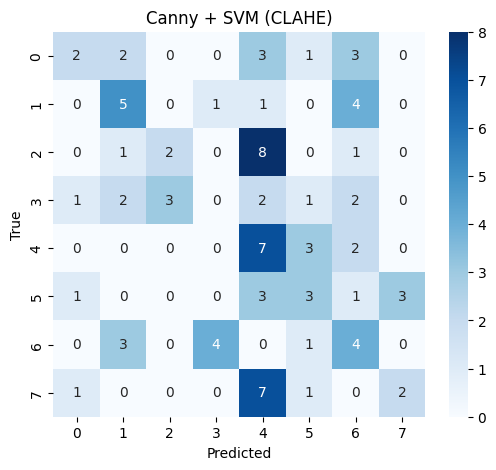

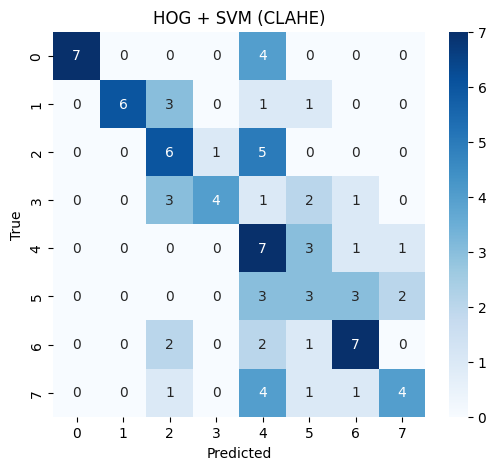

In [44]:
X_train_clahe, X_temp_clahe, y_train_clahe, y_temp_clahe = train_test_split(
    image_clahe, labels,
    test_size=0.3,
    random_state=42,
    stratify=labels
)

X_val_clahe, X_test_clahe, y_val_clahe, y_test_clahe = train_test_split(
    X_temp_clahe, y_temp_clahe,
    test_size=0.5,
    random_state=42,
    stratify=y_temp_clahe
)


X_train_canny_clahe = np.array([flatten_edges(img) for img in X_train_clahe])
X_val_canny_clahe   = np.array([flatten_edges(img) for img in X_val_clahe])

svm_canny_clahe = SVC(kernel='rbf', C=10, gamma='scale')
svm_canny_clahe.fit(X_train_canny_clahe, y_train_clahe)

y_pred_canny_clahe = svm_canny_clahe.predict(X_val_canny_clahe)
acc_canny_clahe = accuracy_score(y_val_clahe, y_pred_canny_clahe)


X_train_hog_clahe = np.array([extract_hog_features(img) for img in X_train_clahe])
X_val_hog_clahe   = np.array([extract_hog_features(img) for img in X_val_clahe])

svm_hog_clahe = SVC(kernel='rbf', C=10, gamma='scale')
svm_hog_clahe.fit(X_train_hog_clahe, y_train_clahe)

y_pred_hog_clahe = svm_hog_clahe.predict(X_val_hog_clahe)
acc_hog_clahe = accuracy_score(y_val_clahe, y_pred_hog_clahe)

print("Canny + SVM:", acc_canny_clahe)
print("HOG + SVM:", acc_hog_clahe)

plot_confusion_matrix(y_val_clahe, y_pred_canny_clahe, "Canny + SVM (CLAHE)")
plot_confusion_matrix(y_val_clahe, y_pred_hog_clahe, "HOG + SVM (CLAHE)")



Canny + SVM (Threshold): 0.23076923076923078
HOG + SVM (Threshold): 0.3956043956043956


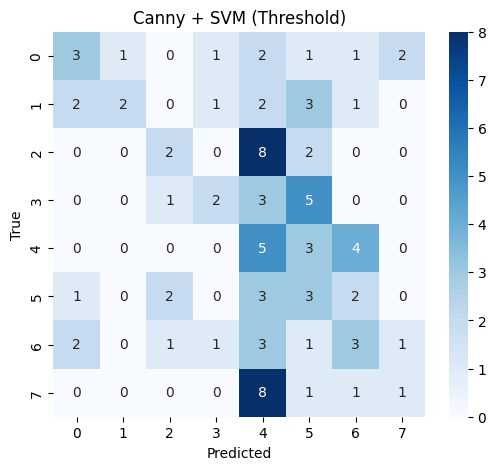

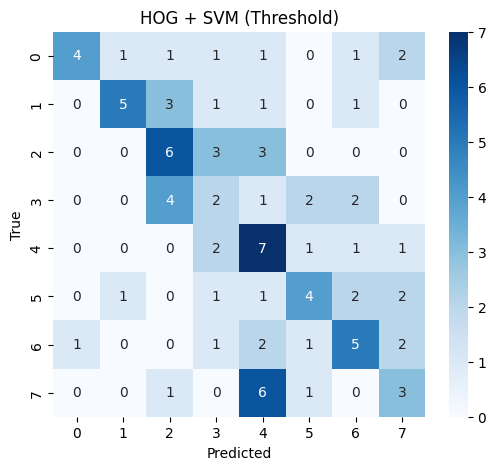

In [52]:
def apply_threshold(img):
    resized = cv2.resize(img, (128, 128))
    grey = cv2.cvtColor(resized, cv2.COLOR_BGR2GRAY)
    gaussian_new = cv2.GaussianBlur(grey, (0, 0), sigmaX=2)
    mean_val = gaussian_new.mean()
    _, labeled_mask = cv2.threshold(gaussian_new, mean_val, 255, cv2.THRESH_BINARY)
    
    return labeled_mask

def threshold_features(img):
    mask = apply_threshold(img)
    return mask.flatten()


def apply_canny(img, t1=100, t2=200):
    edges = cv2.Canny(img, threshold1=t1, threshold2=t2)
    return edges

def flatten_edges(img):
    edges = apply_canny(img, 128)
    return edges.flatten()


def extract_hog_features(img):
    features = hog(img,
                   pixels_per_cell=(8, 8),
                   cells_per_block=(2, 2),
                   orientations=9,
                   block_norm='L2-Hys')
    return features



X_train_thr, X_temp_thr, y_train_thr, y_temp_thr = train_test_split(
    image_threshold, labels,
    test_size=0.3,
    random_state=42,
    stratify=labels
)

X_val_thr, X_test_thr, y_val_thr, y_test_thr = train_test_split(
    X_temp_thr, y_temp_thr,
    test_size=0.5,
    random_state=42,
    stratify=y_temp_thr
)

X_train_canny_thr = np.array([flatten_edges(img) for img in X_train_thr])
X_val_canny_thr   = np.array([flatten_edges(img) for img in X_val_thr])

svm_canny_thr = SVC(kernel='rbf', C=10, gamma='scale')
svm_canny_thr.fit(X_train_canny_thr, y_train_thr)

y_pred_canny_thr = svm_canny_thr.predict(X_val_canny_thr)
acc_canny_thr = accuracy_score(y_val_thr, y_pred_canny_thr)

X_train_hog_thr = np.array([extract_hog_features(img) for img in X_train_thr])
X_val_hog_thr   = np.array([extract_hog_features(img) for img in X_val_thr])


svm_hog_thr = SVC(kernel='rbf', C=10, gamma='scale')
svm_hog_thr.fit(X_train_hog_thr, y_train_thr)

y_pred_hog_thr = svm_hog_thr.predict(X_val_hog_thr)
acc_hog_thr = accuracy_score(y_val_thr, y_pred_hog_thr)

print("Canny + SVM (Threshold):", acc_canny_thr)
print("HOG + SVM (Threshold):", acc_hog_thr)

plot_confusion_matrix(y_val_thr, y_pred_canny_thr, "Canny + SVM (Threshold)")
plot_confusion_matrix(y_val_thr, y_pred_hog_thr, "HOG + SVM (Threshold)")
